<a href="https://colab.research.google.com/github/aswathiunnikrishnan/Assignment--1/blob/main/Assignment07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

LOADING AND PREPARING

In [3]:
#load dataset

cancer = load_breast_cancer()

In [4]:
#convert into dataset

df = pd.DataFrame(cancer.data,columns=cancer.feature_names)

In [7]:
df.head()
df.info()
df.describe()
print("Dataset shape:",df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [10]:
df['target'] = cancer.target

In [11]:
print(df['target'].value_counts())

target
1    357
0    212
Name: count, dtype: int64


In [12]:
#missing values

print(df.isnull().sum())

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64


In [13]:
x= df.drop('target',axis=1)
y= df['target']

In [14]:
#handling missing values by mean imputation

imputer = SimpleImputer(strategy='mean')
x_imputed = imputer.fit_transform(x)

In [15]:
x_train,x_test,y_train,y_test = train_test_split(x_imputed,y,test_size=0.2,random_state=42,stratify=y)

In [16]:
print ("training data:",x_train.shape)
print ("testing data:",x_test.shape)

training data: (455, 30)
testing data: (114, 30)


In [17]:
#feature scaling

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

The original Scikit-learn breast cancer dataset does not contain missing values. However, we can include an imputation step to make the preprocessing pipeline more robust.


Mean imputation replaces missing numerical values with the mean of the respective feature. It helps prevent errors during model training if missing values are present.

Feature scaling is important because the dataset contains features with different measurement ranges.StandardScaler was used for feature scaling because the Breast Cancer dataset contains numerical features with different measurement ranges. It standardises the features by removing the mean and scaling them to unit variance. This helps algorithms such as Logistic Regression, SVM and k-Nearest Neighbors perform more effectively.

CLASSIFICATION  ALGORITHM  IMPLEMENTATION

In [19]:
# 1. Lgistic Regression

from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter = 10000)
lr.fit(x_train_scaled,y_train)


LogisticRegression(max_iter=10000)

In [22]:
lr_pred = lr.predict(x_test_scaled)


logistic regression is suitable for binary classification.
It can predict whether a tumour is malignant or benign.
It is computationally efficient.
It provides probability-based predictions.
Feature scaling helps improve its performance.

In [24]:
# 2. Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42,max_depth=5)
dt.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [25]:
dt_pred = dt.predict(x_test)

Decision tree classifier can handle numerical features such as tumour radius and area.
It identifies important patterns in the dataset.
It is easy to understand and interpret.
It does not require feature scaling.

In [27]:
# 3. Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100,random_state=42)
rf.fit(x_train,y_train)

RandomForestClassifier(random_state=42)

In [28]:
rf_pred = rf.predict(x_test)

Random forest classifier can handle multiple numerical features.
It reduces overfitting compared with a single unrestricted Decision Tree.
It generally provides good classification accuracy.
It can identify important features that influence tumour classification.

In [30]:
# 4. Support Vector Machine

from sklearn.svm import SVC

svm = SVC(kernel='rbf',C=1.0,random_state=42)
svm.fit(x_train_scaled,y_train)

SVC(random_state=42)

In [31]:
svm_pred = svm.predict(x_test_scaled)

SVM works well with high-dimensional datasets.
The Breast Cancer dataset contains 30 features, making SVM a suitable choice.
It can identify complex patterns.
It often performs well when features are properly scaled.

In [32]:
# 5. k-nearest neighbor

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled,y_train)

KNeighborsClassifier()

In [33]:
knn_pred = knn.predict(x_test_scaled)

KNN is useful for binary classification.
It is simple to understand and implement.
It classifies tumours based on similarities in their features.
It can perform well when the features are properly scaled.

MODEL  COMPARISON

In [35]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

# 1. accuracy score

models = {'Logistic Regression':lr_pred,
          'Decision Tree': dt_pred,
          'Random Forest': rf_pred,
          'SVM'          : svm_pred,
          'KNN'          : knn_pred}

In [38]:
accuracy_results = []

for name,preds in models.items():
  accuracy = accuracy_score(y_test,preds)
  accuracy_results.append({'Algorithm': name,
                           'Accuracy score': accuracy,
                           'Accuracy rate(%)': accuracy*100})



In [40]:
accuracy_df = pd.DataFrame(accuracy_results)
print(accuracy_df)

             Algorithm  Accuracy score  Accuracy rate(%)
0  Logistic Regression        0.982456         98.245614
1        Decision Tree        0.921053         92.105263
2        Random Forest        0.956140         95.614035
3                  SVM        0.982456         98.245614
4                  KNN        0.956140         95.614035


In [42]:
#sort models by accuracy

accuracy_df = accuracy_df.sort_values(by='Accuracy rate(%)',ascending=False)
print(accuracy_df.round(2))

             Algorithm  Accuracy score  Accuracy rate(%)
0  Logistic Regression            0.98             98.25
3                  SVM            0.98             98.25
2        Random Forest            0.96             95.61
4                  KNN            0.96             95.61
1        Decision Tree            0.92             92.11


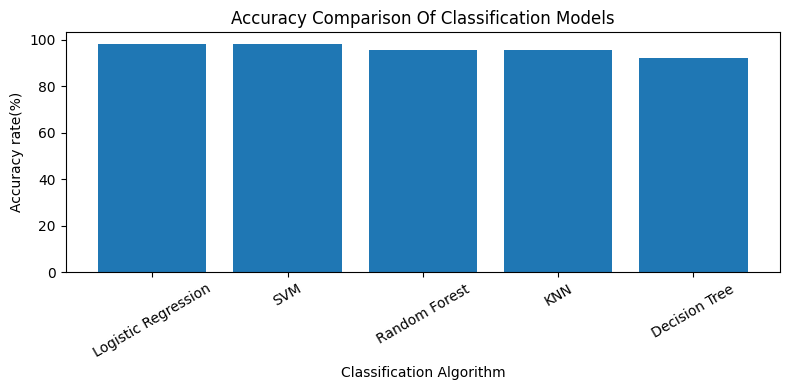

In [44]:
# visualisation

plt.figure(figsize=(8,4))
plt.bar(accuracy_df['Algorithm'],accuracy_df['Accuracy rate(%)'])

plt.title('Accuracy Comparison Of Classification Models')
plt.xlabel('Classification Algorithm')
plt.ylabel('Accuracy rate(%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [46]:
# identify best model

best_model = accuracy_df.iloc[0]
print("best performing model:",best_model['Algorithm'])
print("Accuracy rate:",round(best_model['Accuracy rate(%)'],2),"%")

best performing model: Logistic Regression
Accuracy rate: 98.25 %


The five classification algorithms were compared using accuracy score. The accuracy score measures the percentage of correctly classified observations. Based on the comparison, the model with the highest accuracy rate is **LOGISTIC REGRESSION**. This model demonstrated the strongest overall classification performance on the test dataset.

The worst performing algorithm for this particular dataset is **DECISION TREE CLASSIFIER**.